# Counting objects of a given class

I want to count, say, "how many cars are in this image" without writing a custom detector. The clean way is to use a small pretrained YOLO model (`ultralytics`'s `yolov8n.pt` is ~6MB) — it knows the 80 COCO classes out of the box.

I'm including a contour-based fallback in case `ultralytics` isn't installed in the environment, since that's a bigger dependency than this notebook strictly needs. On a simple image with high-contrast objects the contour count is surprisingly serviceable; on anything realistic, YOLO wins.

In [1]:
# !pip install ultralytics -q  # ~6MB model download on first call

In [2]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../../data/sample_images")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

try:
    from ultralytics import YOLO
    yolo = YOLO("yolov8n.pt")  # auto-downloads on first run
    HAVE_YOLO = True
except Exception as e:
    HAVE_YOLO = False
    yolo = None
    print("ultralytics not available, falling back to contours.", repr(e)[:120])

## Path A: YOLO

If `ultralytics` is around, this is basically a one-liner. I just count detections whose class name matches whatever I asked for, above a confidence threshold.

In [3]:
def count_with_yolo(img_bgr, target_class="person", conf=0.35):
    if not HAVE_YOLO:
        return None, None
    res = yolo.predict(img_bgr, conf=conf, verbose=False)[0]
    names = res.names  # {class_id: 'name'}
    boxes = res.boxes
    hits = [(int(b.cls.item()), float(b.conf.item()), b.xyxy[0].tolist()) for b in boxes]
    matched = [h for h in hits if names[h[0]] == target_class]
    drawn = img_bgr.copy()
    for cls_id, c, (x1,y1,x2,y2) in matched:
        cv2.rectangle(drawn, (int(x1),int(y1)), (int(x2),int(y2)), (0, 220, 0), 2)
        cv2.putText(drawn, f"{names[cls_id]} {c:.2f}", (int(x1), int(y1)-6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 220, 0), 1)
    return len(matched), drawn

## Path B: contour fallback

This only works on images where the objects are visually well-separated from the background. I use it on a synthetic image with dots so we at least see a number.

In [4]:
def count_with_contours(img_bgr, min_area=100):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # close small holes before contouring
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8))
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) > min_area]
    drawn = img_bgr.copy()
    cv2.drawContours(drawn, contours, -1, (0, 0, 220), 2)
    return len(contours), drawn

# synthetic image with 7 "objects" for the fallback demo
def _dots_image():
    img = np.full((300, 400, 3), 245, dtype=np.uint8)
    rng = np.random.default_rng(0)
    for _ in range(7):
        cx, cy = rng.integers(40, 360), rng.integers(40, 260)
        cv2.circle(img, (int(cx), int(cy)), 25, (60, 60, 60), -1)
    return img

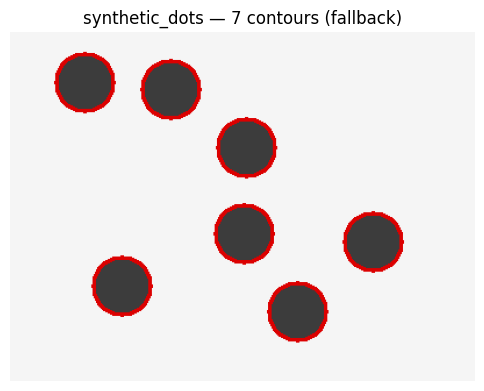

In [5]:
real = sorted([p for p in DATA.glob("*") if p.suffix.lower() in {".jpg",".jpeg",".png"}])

if real and HAVE_YOLO:
    img = cv2.imread(str(real[0]))
    n, drawn = count_with_yolo(img, target_class="person")
    title = f"{real[0].name} — {n} person(s) (YOLO)"
else:
    img = _dots_image()
    n, drawn = count_with_contours(img)
    title = f"synthetic_dots — {n} contours (fallback)"

plt.figure(figsize=(6,5))
plt.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
plt.title(title); plt.axis("off")
plt.savefig(ART/"object_count.png", dpi=110); plt.show()

## Notes

- YOLO is the right tool. The contour version is only there so the notebook still produces output in a clean environment.
- For a real use case (counting items on a shelf, cars in a lot) you'd also want to deal with overlapping boxes — `ultralytics` does NMS internally, but on close-packed objects you can still get double counts.
- I'm not reporting accuracy here. Without a labeled test set, "I counted 7 cars" is a vibe, not a metric.